In [1]:
from pathlib import Path
import os
import time
import jax
import jax.numpy as jnp
import equinox as eqx
import optax
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from fft_thermal_solver import solve_thermal_fft

Setting for the model

In [ ]:
load_weights = True
train_model = False
folder = Path('.')  
checkpoint_path = Path('ufno_trained.eqx')
use_ufno = True  # U-Net branches in the last two blocks
model_name = 'U-FNO' if use_ufno else 'FNO'

#### 1. Parameters

In [ ]:
n = 64  
Lx, Ly = 1.0, 1.0
n_train = 256  # default is 256
n_test = 96    # default is 16
test_start = 9000 
batch_size = 32
n_epochs = 100
width = 32 # feature width, target for the lifting layer
modes = 16 # uploaded checkpoints use 16; original notebook setting was 10
n_blocks = 3 # number of FNO blocks
learning_rate = 0.0009 # Adam learning rate

unet_width = 16  # U-Net channels: 16, 32, 64


Pseudo-random seed

In [4]:
seed = 0

Material properties 

In [5]:
lambda_f = 20.0
phase_contrast = 5.0
lambda_m = lambda_f / phase_contrast
lambda_0 = (lambda_f + lambda_m) / 2.0
print(f"lambda_m = {lambda_m}")
print(f"lambda_0 = {lambda_0}")

lambda_m = 4.0
lambda_0 = 12.0


In [6]:
grad_T_MAC = jnp.array([0.1, 0.0], dtype = jnp.float32)
T_mean = 10.0 
fft_tolerance = 1e-6
fft_max_steps = 1000
# these are for the reference FFT solver 
sample_to_plot = 25 # which test sample to plot   

#### 2. Data and grid

Create a simple physical grid

In [7]:
def make_grid(n, Lx, Ly):
    x = jnp.linspace(0.0, Lx, n, endpoint=False)
    y = jnp.linspace(0.0, Ly, n, endpoint=False)
    return jnp.meshgrid(x, y, indexing='ij')

Load parameters from the given data files

Files used are 'coeff_vec.npy', 'phi0.npy', 'l_data.npy', 'm_data.npy'

Concatenate the relevant parameters into a tensor with shape of: values.shape == (10500, 19)

values[0 -> 15]: coeff_vec

values[16]: phi0

values[17]: l_data

values[18]: m_data

Return the final jnp array with that shape

In [8]:
def load_parameters(folder):
    names = ['coeff_vec.npy', 'phi0.npy', 'l_data.npy', 'm_data.npy']
    missing = [name for name in names if not (folder / name).is_file()]
    
    if missing:
        raise FileNotFoundError(f'Missing beside the script: {", ".join(missing)}')
        
    coeff, phi0, l_data, m_data = [np.load(folder / name, allow_pickle=False) for name in names]

    values = np.concatenate([coeff, phi0.reshape(-1, 1), l_data.reshape(-1, 1), m_data.reshape(-1, 1)], axis=1)

    return jnp.asarray(values, dtype = jnp.float32)

Generate a full material sample for the model

Phi is calculated according to 

$$
\phi(x,y) = \frac{\phi_0}{2}
+ \sum_{f_x=0}^{3}\sum_{f_y=0}^{3}
c_{f_x,f_y}\cos(2\pi f_x x)\cos(2\pi f_y y).
$$

Then, the final factor for the material field is returned as:

$$
E(x,y) = \frac{\sigma\!\left(m(\phi(x,y)-l)\right)+0.05}{1.05},
\qquad
\sigma(z) = \frac{1}{1+e^{-z}}.
$$

In [9]:
def full_sample(parameters, xx, yy):
    # calculate phi0/2 and initialize the phi array. xx is the physical mesh grid
    phi = jnp.ones_like(xx) * parameters[16] / 2.0

    # loop through the 16 coeff_vec
    for fx in range(4): 
        for fy in range(4):
            phi += (parameters[4*fx + fy] * jnp.cos(2*jnp.pi*fx*xx) * jnp.cos(2*jnp.pi*fy*yy))

    l, m = parameters[17], parameters[18]
    return (jax.nn.sigmoid(m*(phi-l)) + 0.05) / 1.05

Compute the actual conductivity for the material field of one sample:

In [10]:
def compute_LAMBDA_MAT(E):
    return lambda_f*E + lambda_m*(1.0-E)

Function to make a full dataset for model training

Output has shape of (no_samples, 3, n, n)

In [11]:
def make_dataset(parameters, xx, yy):
    # Vectorizing
    E = jax.vmap(full_sample, in_axes=(0, None, None))(parameters, xx, yy) # shape (no_samples, n, n)

    return jnp.stack([E, jnp.broadcast_to(xx, E.shape), jnp.broadcast_to(yy, E.shape)], axis=1) 
    # return shape (no_samples, 3, n, n)

Function to create wave vectors kx, ky

In [12]:
def make_wavevectors(n, Lx, Ly):
    kx = 2 * jnp.pi * jnp.fft.fftfreq(n, d=Lx/n)
    ky = 2 * jnp.pi * jnp.fft.fftfreq(n, d=Ly/n)

    kx, ky = jnp.meshgrid(kx, ky, indexing="ij")

    k_squared = kx**2 + ky**2
    safe_k_squared = jnp.where(k_squared == 0, 1.0, k_squared)

    return kx, ky, safe_k_squared


**Creating grids and load parameters using above functions:**

In [13]:
xx, yy = make_grid(n, Lx, Ly)
wavevectors = make_wavevectors(n, Lx, Ly)
parameters = load_parameters(folder)

Shape checkpoint:

In [14]:
print(f'xx.shape = {xx.shape}')
print(f'yy.shape = {yy.shape}')
print(f'wavevectors.shape = {len(wavevectors)}')
print(f'kx.shape = {wavevectors[0].shape}')
print(f'ky.shape = {wavevectors[1].shape}')
print(f'k2.shape = {wavevectors[2].shape}')
print(f'parameters.shape = {parameters.shape}')

xx.shape = (64, 64)
yy.shape = (64, 64)
wavevectors.shape = 3
kx.shape = (64, 64)
ky.shape = (64, 64)
k2.shape = (64, 64)
parameters.shape = (10500, 19)


**Creating data sets for training and testing:**

In [15]:
test_x = make_dataset(parameters[test_start:test_start + n_test], xx, yy)
print(f'test_x.shape = {test_x.shape}')
if train_model:
    train_x = make_dataset(parameters[:n_train], xx, yy)
    print(f'train_x.shape = {train_x.shape}')


test_x.shape = (96, 3, 64, 64)


#### 3. U-FNO

Spectral branch of the FNO block:

In [16]:
class SpectralConv2d(eqx.Module):
    real_weights_pos: jax.Array
    imag_weights_pos: jax.Array
    real_weights_neg: jax.Array
    imag_weights_neg: jax.Array

    
    def __init__(self, width, modes, *, key):
        keys = jax.random.split(key, 4)

        # shape: input feature, output feature, frequency, frequency
        shape = (width, width, modes, modes)

        # scale = 1 / (in_channel * out_channel)
        scale = 1.0 / (width * width)
        arrays = [jax.random.uniform(k, shape, minval = -scale, maxval = scale) for k in keys]

        (self.real_weights_pos, self.imag_weights_pos, self.real_weights_neg, self.imag_weights_neg) = arrays

    

    def __call__(self, x):
        # x.shape = (width, n, n) = (features, grid points in x, grid points in y)
        # x_hat.shape = (width, n, n//2 + 1) -> at n=64: (32, 64, 33)
        
        x_hat = jnp.fft.rfft2(x, axes=(-2,-1))
        m = self.real_weights_pos.shape[-1] # number of retained modes

        w_pos = self.real_weights_pos + 1j * self.imag_weights_pos
        w_neg = self.real_weights_neg + 1j * self.imag_weights_neg

        # for each retained frequency, combine that frequency's weights from all 
        # 32 input features to produce each output feature
        # i=input feature, o=output feature, x/y = frequency indices
        positive = jnp.einsum('ixy,ioxy->oxy', x_hat[:, :m, :m], w_pos)
        negative = jnp.einsum('ixy,ioxy->oxy', x_hat[:, -m:, :m], w_neg)

        out_hat = jnp.zeros_like(x_hat)        
        out_hat = out_hat.at[:, :m, :m].set(positive)
        out_hat = out_hat.at[:, -m:, :m].set(negative)

        return jnp.fft.irfft2(out_hat, s=x.shape[-2:], axes=(-2, -1))
        # return to spatial representation
        # (width, n, n//2 + 1) -> (width, n, n)

U-Net branch:

In [17]:
from typing import Optional

class UNet2d(eqx.Module):
    enc0: eqx.nn.Conv2d
    enc1: eqx.nn.Conv2d
    bottleneck: eqx.nn.Conv2d
    dec1: eqx.nn.Conv2d
    dec0: eqx.nn.Conv2d
    output_conv: eqx.nn.Conv2d

    def __init__(self, width, base_width=16, *, key):
        keys = jax.random.split(key, 6)
        c = base_width
        self.enc0 = eqx.nn.Conv2d(width, c, 3, padding=1,
                                  padding_mode='CIRCULAR', key=keys[0])
        self.enc1 = eqx.nn.Conv2d(c, 2*c, 3, stride=2, padding=1,
                                  padding_mode='CIRCULAR', key=keys[1])
        self.bottleneck = eqx.nn.Conv2d(2*c, 4*c, 3, stride=2, padding=1,
                                        padding_mode='CIRCULAR', key=keys[2])
        self.dec1 = eqx.nn.Conv2d(4*c + 2*c, 2*c, 3, padding=1,
                                  padding_mode='CIRCULAR', key=keys[3])
        self.dec0 = eqx.nn.Conv2d(2*c + c, c, 3, padding=1,
                                  padding_mode='CIRCULAR', key=keys[4])
        self.output_conv = eqx.nn.Conv2d(c, width, 1, key=keys[5])


    def __call__(self, x):
        # Grid sizes must be divisible by four.
        s0 = jax.nn.gelu(self.enc0(x))           # (16,n,n): first skip
        s1 = jax.nn.gelu(self.enc1(s0))          # (32,n/2,n/2): second skip
        z = jax.nn.gelu(self.bottleneck(s1))     # (64,n/4,n/4)

        z = jnp.repeat(jnp.repeat(z, 2, axis=-2), 2, axis=-1)
        z = jnp.concatenate([z, s1], axis=0)    # (96,n/2,n/2)
        z = jax.nn.gelu(self.dec1(z))           # (32,n/2,n/2)

        z = jnp.repeat(jnp.repeat(z, 2, axis=-2), 2, axis=-1)
        z = jnp.concatenate([z, s0], axis=0)    # (48,n,n)
        z = jax.nn.gelu(self.dec0(z))           # (16,n,n)
        return self.output_conv(z)              # (32,n,n): correction

Define a full FNO block as:

In [18]:
class FNOBlock2d(eqx.Module):
    spectral_conv: SpectralConv2d
    bypass_conv: eqx.nn.Conv2d
    unet: Optional[UNet2d]

    def __init__(self, width, modes, *, key, use_unet=False, unet_width=16):
        # Keep the original keys for the original two branches.
        k1, k2 = jax.random.split(key)
        self.spectral_conv = SpectralConv2d(width, modes, key=k1)
        self.bypass_conv = eqx.nn.Conv2d(width, width, kernel_size=1, key=k2)
        self.unet = (UNet2d(width, unet_width, key=jax.random.fold_in(key, 100))
                     if use_unet else None)

    def __call__(self, x):
        y = self.spectral_conv(x) + self.bypass_conv(x)
        if self.unet is not None:
            y = y + self.unet(x)  # new parallel spatial branch
        return jax.nn.gelu(y)

Define a full FNO NN with lifting layer and projection layer:

In [19]:
class FNO2d(eqx.Module):
    lifting: eqx.nn.Conv2d
    fno_blocks: list
    projection: eqx.nn.Conv2d


    def __init__(self, width, modes, n_blocks, *, key, use_ufno=True, unet_width=16):
        keys = jax.random.split(key, n_blocks + 2)

        # lifting layer, 3 inputs -> 32 inputs for FNO blocks 
        self.lifting = eqx.nn.Conv2d(3, width, kernel_size=1, key=keys[0])

        # FNO blocks
        self.fno_blocks = [FNOBlock2d(width, modes, key=keys[i+1],
                       use_unet=use_ufno and i >= n_blocks-2,
                       unet_width=unet_width) for i in range(n_blocks)]

        # projection layer, 32 ouputs -> 2 outputs
        self.projection = eqx.nn.Conv2d(width, 2, kernel_size=1, key=keys[-1])


    def __call__(self, x):
        x = self.lifting(x)
        # (3, n, n) -> (width, n, n)

        for block in self.fno_blocks:
            x = block(x)

        return self.projection(x)
        # (2, n, n): dT/dx, dT/dy

#### 4. Loss function

Shape checkpoint:


lambda_field: (n, n) -> (64, 64) at the baseline

grad_T_REAL: (2, n, n) -> (2, 64, 64), 2 for dT/dx, dT/dy

each array in wavevectors (n, n)

lambda_0: scalar

**Temperature-gradient fluctuation in Fourier space is calculated as:**

$$
\widehat{\widetilde{\mathbf{g}}}(\mathbf{k})
=
\frac{\mathbf{k}\left(\mathbf{k}\cdot\widehat{\mathbf{P}}(\mathbf{k})\right)}
{\lambda_0|\mathbf{k}|^2},
\qquad \mathbf{k}\ne\mathbf{0},
\qquad
\widehat{\widetilde{\mathbf{g}}}(\mathbf{0})=\mathbf{0}.
$$

The mean part is added later on using grad_T_MAC. This calculates only the fluctuation part.

In [20]:
@jax.jit
def Loss_FFT(lambda_field, grad_T_REAL, wavevectors):
    kx, ky, k_squared = wavevectors
    Q_REAL = -lambda_field[None, :, :] * grad_T_REAL
    # heat flux, Q_REAL has shape of (2, n, n)
    
    P_REAL = lambda_0 * grad_T_REAL + Q_REAL
    # perturbation field, P_REAL with shape (2, n, n)
    
    P_FFT = jnp.fft.fft2(P_REAL, axes=(-2,-1))
    # transform into Fourier space, P_FFT.shape == (2, n, n)
    # note, fft2 is used here, not rfft2. Notice the shape to be (2, n, n)
    # not (2, n, n//2 + 1)
    
    k_dot_P = kx*P_FFT[0] + ky*P_FFT[1]
    # k_dot_P.shape = (n, n)
    
    grad_T_FFT = jnp.stack([kx*k_dot_P, ky*k_dot_P]) / (lambda_0 * k_squared)
    grad_T_FFT = grad_T_FFT.at[:, 0, 0].set(0.0)
    
    return jnp.fft.ifft2(grad_T_FFT, axes=(-2,-1)).real
    # (2, n, n), ifft2 accordingly to return to spatial space

Since: predicted gradient = FFT-calculated fluctuation + imposed mean gradient

The residual is defined as 'predicted gradient' - 'FFT-calculated fluctuation' - 'imposed mean gradient'

The loss is then calculated as the average over all samples in the batch, both gradient components and all grid points.

Shape check: 

inputs (batch_size, 3, n, n), 3 for material field E, x and y coordinates

wavevectors: tuple of three (n, n) arrays

grad_T_MAC: (2,)


In [21]:
def loss_fn(model, inputs, wavevectors):
    g_pred = jax.vmap(model)(inputs)
    # predict the gradient for every sample in the batch
    # g_pred.shape == (batch_size, 2, n, n)
    
    conductivity = compute_LAMBDA_MAT(inputs[:, 0, :, :])
    # convert the material field into conductivity. conductivity.shape == (batch_size, n, n)
    # inputs[:, 0, :, :] to extract E of every gridpoint of every sample in the batch
    
    g_fluctuation = jax.vmap(Loss_FFT, in_axes=(0, 0, None))(conductivity, g_pred, wavevectors)
    # applied Loss_FFT to every g_pred
    # in_axes=(0,0,None) as in select the conductivity and g_pred of the 0 axis (sample no. in the batch)
    # to map; None to reuse the same wavevectors
    # g_fluctuation.shape == (batch_size, 2, n, n)
    
    residual = g_pred - g_fluctuation - grad_T_MAC[None, :, None, None]
    return jnp.mean(residual**2)

#### 5. Optimizer and creating model

In [22]:
lr_schedule = optax.exponential_decay(
    init_value=learning_rate,
    transition_steps=2000,
    decay_rate=0.9,
    staircase=False,
)

optimizer = optax.adam(lr_schedule)

Perform one training step on one batch:

1. Calculate the loss and its gradients w.r.t the model's weights
2. Optimizer updates the weights
3. Return the updated model, updated optimizer state and loss

Shape:
- inputs.shape == (batch_size, 3, n, n)
- loss: scalar
- gradients: same shape as the weights

In [23]:
@eqx.filter_jit
def make_step(model, opt_state, inputs, wavevectors):
    loss, gradients = eqx.filter_value_and_grad(loss_fn)(model, inputs, wavevectors)
    updates, opt_state = optimizer.update(gradients, opt_state, model)
    return eqx.apply_updates(model, updates), opt_state, loss

Creating RNG keys

In [24]:
key_model, key_shuffle = jax.random.split(jax.random.PRNGKey(seed))

**Construct the model and load the checkpoint when requested.** Re-running this cell resets the model and reloads the saved weights when `load_weights=True`.

In [25]:
model = FNO2d(width, modes, n_blocks, key=key_model,
              use_ufno=use_ufno, unet_width=unet_width)
# creating new model

if load_weights:
    with checkpoint_path.open('rb') as checkpoint_file:
        model = eqx.tree_deserialise_leaves(checkpoint_file, model)
    print(f'Loaded trained weights: {checkpoint_path}')

opt_state = optimizer.init(eqx.filter(model, eqx.is_array)) if train_model else None

Loaded trained weights: ufno_trained.eqx


In [26]:
arrays = jax.tree_util.tree_leaves(eqx.filter(model, eqx.is_array))
total = sum(array.size for array in arrays)
print(f"Total parameters: {total:,}")

Total parameters: 3,274,914


Define the batched prediction function. 

In [27]:
@eqx.filter_jit
def evaluate(network, inputs):
    batched_network = jax.vmap(network)
    predictions = batched_network(inputs)
    return predictions

#### 6. Training

In [28]:
loss_history = []
if train_model:
    # Progress is also written to a separate file for tracking on HPC
    progress_id = os.environ.get("SLURM_JOB_ID", "local_" + time.strftime("%Y%m%d_%H%M%S"))
    progress_file = Path("training_progress_" + progress_id + ".txt")
    training_start = time.perf_counter()
    progress_file.write_text(f"Training started: {n_epochs} epochs, {n_train} samples, batch size {batch_size}\n")
    print(f"Live progress: {progress_file.resolve()}", flush=True)
    
    for epoch in range(n_epochs):
        epoch_start = time.perf_counter()
        key_shuffle, key = jax.random.split(key_shuffle)
        order = jax.random.permutation(key, n_train)
        # shuffle the order of the train_x samples
        
        weighted_loss = 0.0
    
        for i in range(0, n_train, batch_size):
        # loop over the batches
            batch = train_x[order[i:i+batch_size]]
            # select the current batch
            
            model, opt_state, loss = make_step(model, opt_state, batch, wavevectors)
            # update model using the selected batch
            weighted_loss += float(loss) * batch.shape[0]
            # batch.shape[0] returns the number of samples in the batch
            # note that loss is already averaged over the batch size so 
            # it's necessary to * with the batch size
            
        loss_history.append(weighted_loss / n_train)
        # store epoch's average loss
        
        epoch_seconds = time.perf_counter() - epoch_start
        elapsed_seconds = time.perf_counter() - training_start
        message = (
            f"Epoch {epoch+1}/{n_epochs} | Loss: {loss_history[-1]:.6e} | "
            f"Epoch time: {epoch_seconds:.1f} s | "
            f"Elapsed: {elapsed_seconds / 60:.1f} min"
        )
        print(message, flush=True)
        with progress_file.open("a") as progress_log:
            progress_log.write(message + "\n")
    
    with progress_file.open("a") as progress_log:
        progress_log.write("Training complete. Continuing to notebook post-processing.\n")
else:
    print('Training skipped; evaluating the loaded weights.')


Training skipped; evaluating the loaded weights.


Save training results

In [29]:
if train_model:
    run_dir = Path("results") / model_name / os.environ.get("SLURM_JOB_ID", "local")
    run_dir.mkdir(parents=True, exist_ok=True)
    
    eqx.tree_serialise_leaves(run_dir / "ufno_trained.eqx", model)
    np.save(run_dir / "loss_history.npy", np.asarray(loss_history))

else:
    print("Loading weights, training skipped")


Loading weights, training skipped


#### 7. Post processing

The thermal solver from the case study is extracted and used as the reference solver 

In [30]:
def solve_fft(conductivity, wavevectors):
    return solve_thermal_fft(conductivity, wavevectors, grad_T_MAC, lambda_0, tol=fft_tolerance, max_iter=fft_max_steps)

Function to compute the relative L2 error

In [31]:
def relative_l2(prediction, reference):
    axes = tuple(range(1, prediction.ndim))
    numerator = jnp.sqrt(jnp.sum((prediction - reference)**2, axis=axes))
    denominator = jnp.sqrt(jnp.sum(reference**2, axis=axes))
    return numerator / jnp.maximum(denominator, 1e-12)

Testing the model accuracy

In [32]:
test_x.shape

(96, 3, 64, 64)

In [33]:
g_pred = evaluate(model, test_x)  # (n_test, 2, n, n)
conductivity = compute_LAMBDA_MAT(test_x[:, 0])  # (n_test, n, n)
references = [solve_fft(k, wavevectors) for k in conductivity]
g_reference = jnp.stack([result[0] for result in references])  # (n_test, 2, n, n)
fft_steps = np.array([result[1] for result in references])
fft_residuals = np.array([result[2] for result in references])


In [34]:
error = relative_l2(g_pred, g_reference) # 16 errors for 16 test samples
mean_error = jnp.mean(jnp.abs(jnp.mean(g_pred, axis=(-2, -1))- grad_T_MAC)) # mean error of the whole field compared to the prescribed macroscopic values

**Printing error values**

In [35]:
print(f'{model_name}: baseline evaluation at {n} x {n}')
print(f'Mean gradient relative L2 error: {100 * float(jnp.mean(error)):.4f}%')
print(f'Mean error of spatial average vs. prescribed gradient: {float(mean_error):.6e}')
print(f'Max FFT reference residual: {fft_residuals.max():.3e}')


U-FNO: baseline evaluation at 64 x 64
Mean gradient relative L2 error: 0.4185%
Mean error of spatial average vs. prescribed gradient: 1.520177e-05
Max FFT reference residual: 9.798e-07


#### 8. Plotting

In [36]:
def draw_field(fig, ax, xx, yy, field, title, color_map, vmin=None, vmax=None):
    plot = ax.pcolormesh(np.asarray(xx), np.asarray(yy), np.asarray(field),
                         shading='auto', cmap=color_map, vmin=vmin, vmax=vmax)
    ax.set(title=title, xlabel='x', ylabel='y', aspect='equal')
    fig.colorbar(plot, ax=ax, shrink=0.85)

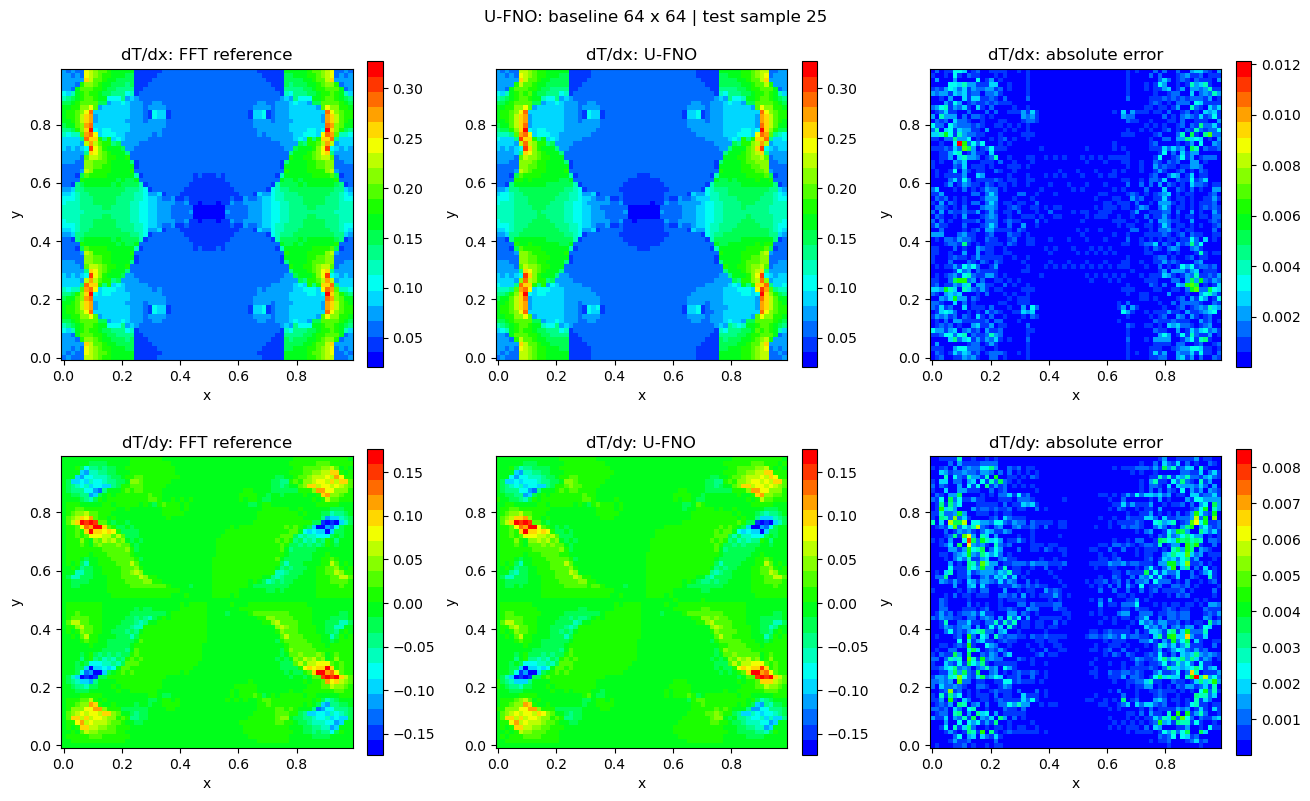

In [37]:
color_values = np.loadtxt(folder / 'FFT_color_coding.txt').reshape(-1, 3)
color_map = ListedColormap(color_values, name='original_FFT_colors')
s = sample_to_plot
fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
fig.suptitle(f'{model_name}: baseline {n} x {n} | test sample {s}')
for component, label in enumerate(['dT/dx', 'dT/dy']):
    ref, pred = g_reference[s, component], g_pred[s, component]
    lo, hi = float(jnp.minimum(ref.min(), pred.min())), float(jnp.maximum(ref.max(), pred.max()))
    draw_field(fig, axes[component, 0], xx, yy, ref, f'{label}: FFT reference', color_map, lo, hi)
    draw_field(fig, axes[component, 1], xx, yy, pred, f'{label}: {model_name}', color_map, lo, hi)
    draw_field(fig, axes[component, 2], xx, yy, jnp.abs(pred-ref), f'{label}: absolute error', color_map)
plt.show()


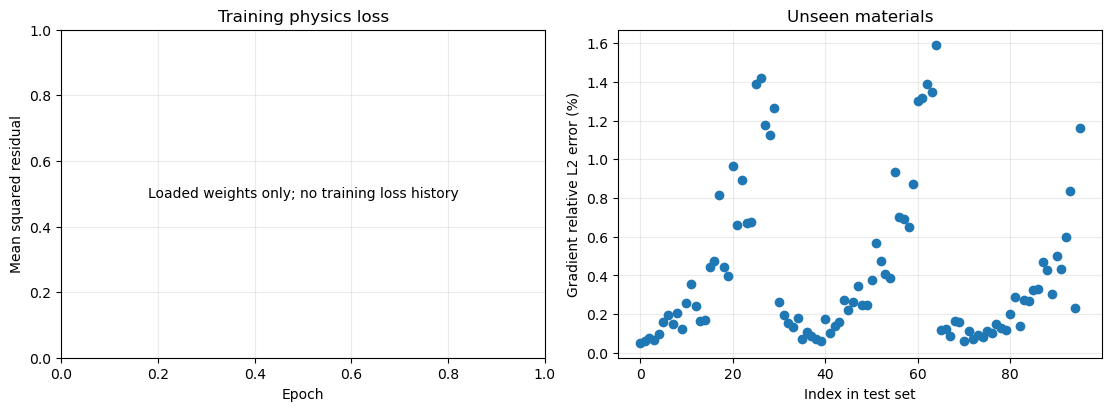

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
if len(loss_history):
    axes[0].semilogy(np.arange(1, len(loss_history) + 1), loss_history)
else:
    axes[0].text(0.5, 0.5, 'Loaded weights only; no training loss history',
                 ha='center', va='center', transform=axes[0].transAxes)
axes[0].set(title='Training physics loss', xlabel='Epoch', ylabel='Mean squared residual')
axes[1].plot(np.arange(n_test), 100*np.asarray(error), 'o')
axes[1].set(title='Unseen materials', xlabel='Index in test set', ylabel='Gradient relative L2 error (%)')
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()


#### 9. Zero-shot superresolution

In [39]:
n_sr = 256  # higher resolution; the checkpoint was trained at 64 x 64

xx_sr, yy_sr = make_grid(n_sr, Lx, Ly)
wavevectors_sr = make_wavevectors(n_sr, Lx, Ly)
test_x_sr = make_dataset(parameters[test_start:test_start + n_test], xx_sr, yy_sr)
# test_x_sr: (n_test, 3, n_sr, n_sr) = (16, 3, 256, 256)


In [40]:
g_pred_sr = evaluate(model, test_x_sr)
# g_pred_sr: (n_test, 2, n_sr, n_sr) = (16, 2, 256, 256)

conductivity_sr = compute_LAMBDA_MAT(test_x_sr[:, 0])
references_sr = [solve_fft(k, wavevectors_sr) for k in conductivity_sr]
g_reference_sr = jnp.stack([result[0] for result in references_sr])
# g_reference_sr has the same shape as g_pred_sr.


In [41]:
error_sr = relative_l2(g_pred_sr, g_reference_sr)
mean_error_sr = jnp.mean(jnp.abs(jnp.mean(g_pred_sr, axis=(-2, -1)) - grad_T_MAC))

print(f'{n} x {n}: mean relative L2 error = {100 * float(jnp.mean(error)):.4f}%')
print(f'{n_sr} x {n_sr}: mean relative L2 error = {100 * float(jnp.mean(error_sr)):.4f}%')
print(f'{n_sr} x {n_sr}: mean error of spatial average = {float(mean_error_sr):.6e}')


64 x 64: mean relative L2 error = 0.4185%
256 x 256: mean relative L2 error = 3.5545%
256 x 256: mean error of spatial average = 2.466232e-05


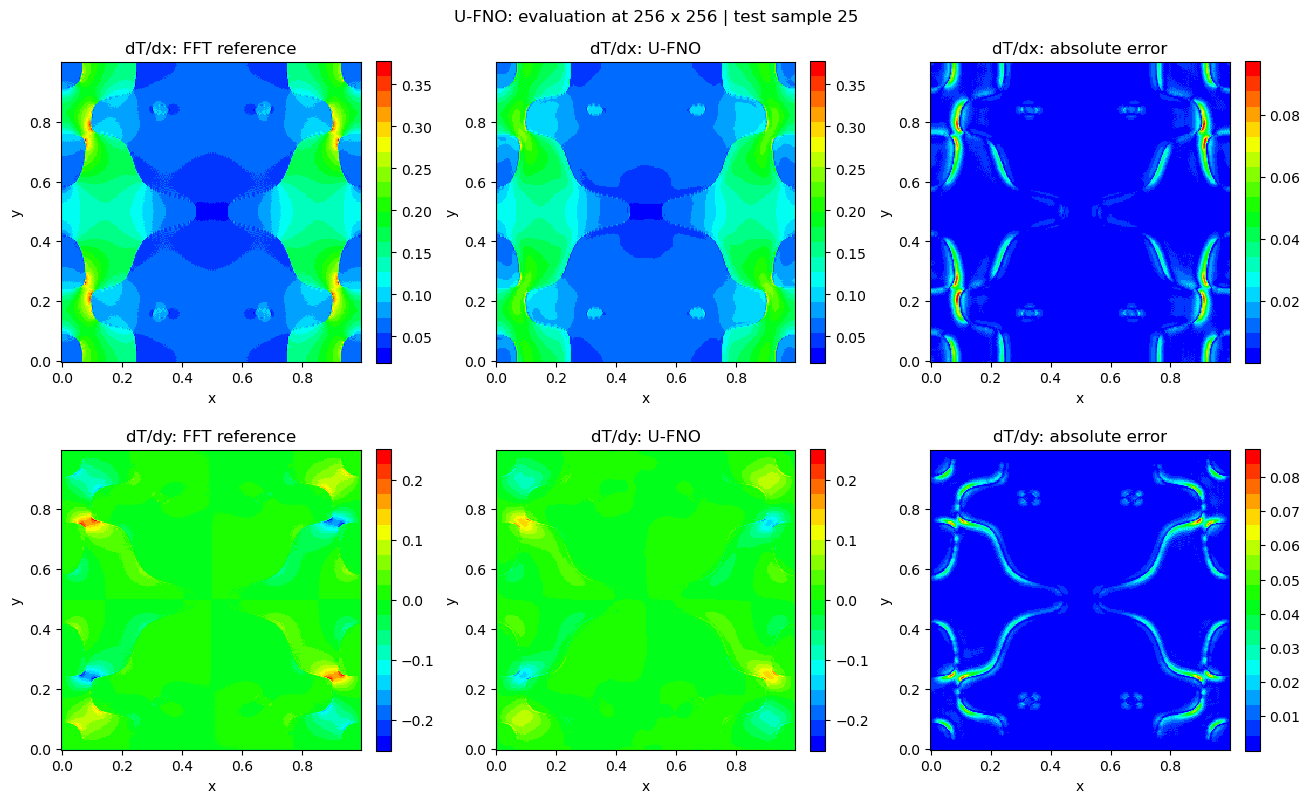

In [42]:
s = sample_to_plot
fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
fig.suptitle(f'{model_name}: evaluation at {n_sr} x {n_sr} | test sample {s}')
for component, label in enumerate(['dT/dx', 'dT/dy']):
    ref, pred = g_reference_sr[s, component], g_pred_sr[s, component]
    lo = float(jnp.minimum(ref.min(), pred.min()))
    hi = float(jnp.maximum(ref.max(), pred.max()))
    draw_field(fig, axes[component, 0], xx_sr, yy_sr, ref,
               f'{label}: FFT reference', color_map, lo, hi)
    draw_field(fig, axes[component, 1], xx_sr, yy_sr, pred,
               f'{label}: {model_name}', color_map, lo, hi)
    draw_field(fig, axes[component, 2], xx_sr, yy_sr, jnp.abs(pred - ref),
               f'{label}: absolute error', color_map)
plt.show()


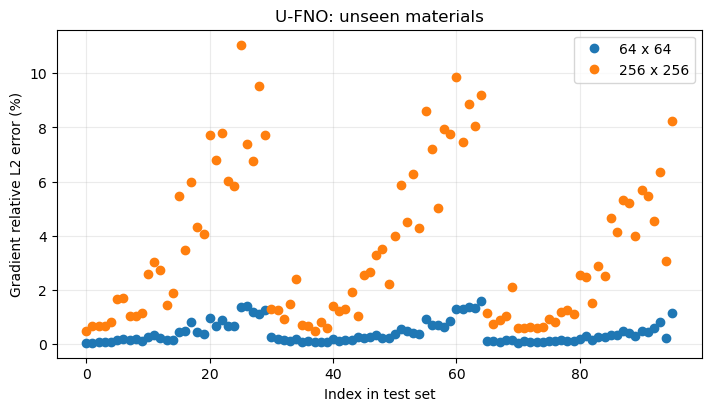

In [43]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(np.arange(n_test), 100 * np.asarray(error), 'o', label=f'{n} x {n}')
ax.plot(np.arange(n_test), 100 * np.asarray(error_sr), 'o', label=f'{n_sr} x {n_sr}')
ax.set(title=f'{model_name}: unseen materials', xlabel='Index in test set',
       ylabel='Gradient relative L2 error (%)')
ax.legend()
ax.grid(alpha=0.25)
plt.show()
